# Explore the Dataversity survey responses

Load the CSV into a pandas DataFrame, inspect its columns and missing values, then use the examples below as a starting point for filtering and summarizing responses.

In [65]:
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import f as f_distribution
from scipy.stats import f_oneway, fisher_exact, spearmanr

from mast_toolkit_notebooks.utils import (
    display_original_correlations,
    parse_choices,
    plot_positive_metrics_by_category,
)

PROJECT_NAME = "dataversity-2026"
data_dir = Path("data") / PROJECT_NAME
if not data_dir.exists():
    data_dir = Path("../data") / PROJECT_NAME

responses_file = data_dir / "dataversity_survey_2iyUvU5Z4Pdi25fBvXwQsJ_responses.csv"
metadata_file = data_dir / "dataversity_metadata.csv"

responses = pd.read_csv(responses_file)
metadata = pd.read_csv(metadata_file)
metadata["choices_parsed"] = metadata["choices (if applicable)"].apply(parse_choices)
print(f"Loaded {len(responses):,} responses from {responses_file}")
print(
    f"Loaded metadata for {len(metadata)} fields; "
    f"{metadata['choices_parsed'].str.len().gt(0).sum()} fields have choices."
)

Loaded 178 responses from ../data/dataversity-2026/dataversity_survey_2iyUvU5Z4Pdi25fBvXwQsJ_responses.csv
Loaded metadata for 40 fields; 28 fields have choices.


In [53]:
# Inspect the table before transforming it
print("Shape:", responses.shape)
print("Columns:", responses.columns.tolist())
responses.info()

missing_by_column = responses.isna().sum().sort_values(ascending=False)
display(missing_by_column[missing_by_column > 0].to_frame("missing values"))

Shape: (178, 40)
Columns: ['id', 'team', 'response_date', 'is_complete', 'tools', 'industry', 'number_of_employees', 'job_category', 'geography', 'other_data_activity', 'data_used_or_created', 'beliefs_metadata_1', 'beliefs_metadata_2', 'beliefs_analysis_1', 'beliefs_analysis_2', 'beliefs_standards_1', 'beliefs_standards_2', 'beliefs_teamwork_1', 'beliefs_teamwork_2', 'actions_inventory_1', 'actions_inventory_2', 'actions_inventory_qual', 'actions_document_1', 'actions_document_2', 'actions_document_qual', 'actions_endorse_1', 'actions_endorse_2', 'actions_endorse_qual', 'actions_audit_1', 'actions_audit_2', 'actions_audit_qual', 'actions_leadership_1', 'actions_leadership_2', 'actions_leadership_qual', 'self_assess_value', 'self_assess_trust', 'self_assess_secure', 'ai_readiness', 'ai_results', 'ai_responsibility']
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 40 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------             

,missing values
team,178
data_used_or_created,178
actions_audit_qual,167
actions_leadership_qual,167
actions_endorse_qual,166
other_data_activity,163
actions_document_qual,151
actions_inventory_qual,146
tools,136
industry,57


# Preprocessing

Add an analysis column for action metrics that prevents analysis on option "1" which is the "i dont do this" column.


In [66]:
# Work on a copy so the original imported data stays unchanged.
analysis_df = responses.copy()

# Recode ratings for display while retaining their numeric source columns.
NEGATIVE = [1, 2]
NEUTRAL = [3]
POSITIVE = [4, 5]
DONT_KNOW = 9
recode_map = {
    **{value: "negative" for value in NEGATIVE},
    **{value: "neutral" for value in NEUTRAL},
    **{value: "positive" for value in POSITIVE},
    DONT_KNOW: "don't know",
}

analysis_df["response_date"] = pd.to_datetime(analysis_df["response_date"], errors="coerce", utc=True)

rating_columns = [
    column
    for column in analysis_df.columns
    if column.startswith(("beliefs_", "actions_", "self_assess_", "ai_"))
    and not column.endswith(("_qual", "_recoded", "_excluding_1"))
]
analysis_df[rating_columns] = analysis_df[rating_columns].apply(pd.to_numeric, errors="coerce")

action_columns = [column for column in rating_columns if column.startswith("actions_")]
action_analysis_columns = {
    column: f"{column}_excluding_1" for column in action_columns
}
for column, analysis_column in action_analysis_columns.items():
    analysis_df[analysis_column] = analysis_df[column].mask(analysis_df[column].eq(1))

recode_columns = [
    column
    for column in rating_columns
    if column.startswith(("beliefs_", "self_assess_", "ai_"))
]
for column in recode_columns:
    analysis_df[f"{column}_recoded"] = analysis_df[column].map(recode_map)

display(analysis_df[[*action_columns[:2], *[action_analysis_columns[column] for column in action_columns[:2]]]].head())
display(analysis_df[[*recode_columns, *[f"{column}_recoded" for column in recode_columns]]].head())

# Example: filter to completed responses and count them by industry.
completed = analysis_df.loc[
    analysis_df["is_complete"].astype("string").str.casefold().eq("true")
]
display(completed["industry"].value_counts(dropna=False).head(10).to_frame("responses"))

,actions_inventory_1,actions_inventory_2,actions_inventory_1_excluding_1,actions_inventory_2_excluding_1
0,2.0,2.0,2.0,2.0
1,NaN,NaN,NaN,NaN
2,5.0,5.0,5.0,5.0
3,NaN,NaN,NaN,NaN
4,4.0,4.0,4.0,4.0


,beliefs_metadata_1,beliefs_metadata_2,beliefs_analysis_1,beliefs_analysis_2,beliefs_standards_1,beliefs_standards_2,beliefs_teamwork_1,beliefs_teamwork_2,self_assess_value,self_assess_trust,...,beliefs_standards_1_recoded,beliefs_standards_2_recoded,beliefs_teamwork_1_recoded,beliefs_teamwork_2_recoded,self_assess_value_recoded,self_assess_trust_recoded,self_assess_secure_recoded,ai_readiness_recoded,ai_results_recoded,ai_responsibility_recoded
0,4,2,2,1,2,2,2,3,4,3,...,negative,negative,negative,neutral,positive,neutral,positive,negative,neutral,negative
1,3,4,5,5,3,3,3,5,5,2,...,neutral,neutral,neutral,positive,positive,negative,neutral,positive,positive,neutral
2,4,3,4,4,4,3,4,4,5,4,...,positive,neutral,positive,positive,positive,positive,positive,neutral,positive,neutral
3,4,4,4,4,4,4,4,4,4,4,...,positive,positive,positive,positive,positive,positive,positive,positive,positive,positive
4,5,4,4,4,4,3,4,5,4,4,...,positive,neutral,positive,positive,positive,positive,positive,positive,negative,don't know


,responses
industry,
Government,22
Banking,15
Finance,14
Healthcare,10
Utilities,10
Education,9
Technology,8
Insurance,8
Energy,5


## AI and self-assessment outcome differences across action ratings

One-way ANOVA tests whether the mean original AI or self-assessment outcome score differs across action ratings `2`, `3`, `4`, and `5`. Action rating `1` (“I don't do this”) and outcome “don't know” (`9`) are excluded. Results are shown when the observed F statistic exceeds the 5% upper-tail critical F value for that test's degrees of freedom: `F_critical = F.ppf(0.95, df_between, df_within)`. Reference: *The Statistical Sleuth*, 2nd ed., p. 125. Displayed p-values are unadjusted across tests.

In [55]:
alpha = 0.05
anova_outcome_columns = [*ai_columns, *self_assess_columns]
anova_rows = []
for action_column, analysis_action_column in action_analysis_columns.items():
    for outcome_column in anova_outcome_columns:
        paired = completed[[analysis_action_column, outcome_column]].replace(
            9, float("nan")
        ).dropna()
        paired = paired.loc[paired[analysis_action_column].isin([2, 3, 4, 5])]
        groups = {
            rating: paired.loc[
                paired[analysis_action_column] == rating, outcome_column
            ].to_numpy()
            for rating in [2, 3, 4, 5]
        }
        nonempty_groups = [values for values in groups.values() if len(values) > 0]

        if len(nonempty_groups) >= 2:
            result = f_oneway(*nonempty_groups)
            total_n = sum(len(values) for values in nonempty_groups)
            df_between = len(nonempty_groups) - 1
            df_within = total_n - len(nonempty_groups)
            f_critical = f_distribution.ppf(1 - alpha, df_between, df_within)
            row = {
                "action": action_column,
                "outcome": outcome_column,
                "f_statistic": result.statistic,
                "f_critical": f_critical,
                "df_between": df_between,
                "df_within": df_within,
                "p_value": result.pvalue,
            }
            for rating, values in groups.items():
                row[f"n_rating_{rating}"] = len(values)
                row[f"mean_rating_{rating}"] = values.mean() if len(values) else float("nan")
            anova_rows.append(row)

anova_results = pd.DataFrame(anova_rows)
for outcome_column in anova_outcome_columns:
    outcome_results = anova_results.loc[
        (anova_results["outcome"] == outcome_column)
        & (anova_results["f_statistic"] > anova_results["f_critical"])
    ].sort_values("f_statistic", ascending=False)
    display(Markdown(f"### {outcome_column}"))
    display(
        outcome_results.drop(columns="outcome").reset_index(drop=True).style.format(
            {
                "f_statistic": "{:.3f}",
                "f_critical": "{:.3f}",
                "df_between": "{:.0f}",
                "df_within": "{:.0f}",
                "p_value": "{:.4g}",
            }
            | {f"mean_rating_{rating}": "{:.2f}" for rating in [2, 3, 4, 5]},
            na_rep="n/a",
        )
    )

### ai_readiness

,action,f_statistic,f_critical,df_between,df_within,p_value,n_rating_2,mean_rating_2,n_rating_3,mean_rating_3,n_rating_4,mean_rating_4,n_rating_5,mean_rating_5
0,actions_leadership_2,9.406,2.695,3,101,1.54e-05,39,2.00,36,2.22,21,3.00,9,3.56
1,actions_endorse_1,8.896,2.696,3,100,2.788e-05,29,1.72,32,2.34,20,2.55,23,3.04
2,actions_endorse_2,6.178,2.709,3,87,0.000742,31,1.94,29,2.31,13,2.69,18,3.17
3,actions_document_1,3.967,2.695,3,101,0.01018,11,1.82,32,2.28,34,2.35,28,2.93
4,actions_inventory_1,3.432,2.694,3,102,0.01983,52,2.12,18,2.78,11,2.64,25,2.72
5,actions_audit_2,3.341,2.704,3,92,0.02264,31,2.06,26,2.46,16,2.94,23,2.78
6,actions_leadership_1,2.799,2.690,3,106,0.04363,31,2.00,18,2.44,10,2.80,51,2.65


### ai_results

,action,f_statistic,f_critical,df_between,df_within,p_value,n_rating_2,mean_rating_2,n_rating_3,mean_rating_3,n_rating_4,mean_rating_4,n_rating_5,mean_rating_5
0,actions_endorse_1,7.108,2.696,3,99,0.0002253,29,1.93,31,2.35,20,2.80,23,3.17
1,actions_leadership_2,4.890,2.697,3,98,0.003281,38,2.13,35,2.60,20,2.80,9,3.56
2,actions_endorse_2,4.348,2.711,3,86,0.006682,30,2.10,29,2.48,12,2.58,19,3.26


### ai_responsibility

...

,action,f_statistic,f_critical,df_between,df_within,p_value,n_rating_2,mean_rating_2,n_rating_3,mean_rating_3,n_rating_4,mean_rating_4,n_rating_5,mean_rating_5
0,actions_leadership_2,9.988,2.691,3,105,7.554e-06,41,2.44,36,2.56,23,3.70,9,3.67
1,actions_endorse_1,8.032,2.690,3,106,7.132e-05,30,2.07,33,2.82,22,3.05,25,3.44
2,actions_endorse_2,7.947,2.704,3,92,9.068e-05,31,2.19,30,2.63,13,3.23,22,3.55
3,actions_inventory_1,6.203,2.690,3,106,0.0006355,53,2.32,18,2.94,12,3.25,27,3.30
4,actions_document_1,6.008,2.690,3,106,0.0008057,11,2.00,33,2.33,35,2.89,31,3.26
5,actions_audit_2,5.878,2.699,3,96,0.0009979,31,2.35,27,2.59,17,2.82,25,3.52
6,actions_leadership_1,5.000,2.686,3,112,0.00272,31,2.23,18,2.72,12,3.08,55,3.16
7,actions_audit_1,4.890,2.696,3,100,0.003257,27,2.33,29,2.76,25,2.56,23,3.48
8,actions_inventory_2,3.409,2.691,3,105,0.02031,20,2.40,35,2.54,23,2.83,31,3.29


### self_assess_trust

,action,f_statistic,f_critical,df_between,df_within,p_value,n_rating_2,mean_rating_2,n_rating_3,mean_rating_3,n_rating_4,mean_rating_4,n_rating_5,mean_rating_5
0,actions_leadership_2,8.804,2.690,3,106,2.898e-05,41,3.02,36,3.28,23,4.13,10,4.10
1,actions_endorse_1,7.411,2.690,3,106,0.0001488,29,2.83,33,3.18,23,3.87,25,3.80
2,actions_document_1,7.026,2.690,3,106,0.0002355,11,2.55,33,3.06,35,3.37,31,3.90
3,actions_inventory_1,6.809,2.690,3,106,0.0003056,53,2.96,18,3.44,12,3.67,27,3.93
4,actions_endorse_2,6.339,2.704,3,92,0.0005909,31,2.90,29,3.41,14,3.93,22,3.95
5,actions_leadership_1,6.043,2.686,3,112,0.0007491,31,2.81,18,3.56,11,3.64,56,3.70
6,actions_audit_1,5.656,2.695,3,101,0.001269,28,2.93,29,3.31,25,3.20,23,4.04
7,actions_inventory_2,5.399,2.690,3,106,0.001699,20,2.75,36,3.31,23,3.43,31,3.87
8,actions_document_2,5.097,2.695,3,101,0.002515,25,2.76,19,3.32,37,3.57,24,3.75
9,actions_audit_2,4.468,2.699,3,96,0.005558,31,3.10,27,3.22,17,3.35,25,4.00


### self_assess_secure

,action,f_statistic,f_critical,df_between,df_within,p_value,n_rating_2,mean_rating_2,n_rating_3,mean_rating_3,n_rating_4,mean_rating_4,n_rating_5,mean_rating_5
0,actions_endorse_1,7.236,2.691,3,105,0.0001846,29,3.52,32,3.59,23,4.43,25,4.32
1,actions_inventory_2,6.845,2.691,3,105,0.0002945,20,3.30,35,3.66,23,4.35,31,4.26
2,actions_endorse_2,5.436,2.705,3,91,0.001748,30,3.50,29,3.90,14,4.64,22,4.23
3,actions_leadership_2,4.928,2.691,3,105,0.00305,40,3.62,36,3.81,23,4.48,10,4.40
4,actions_document_1,2.947,2.691,3,105,0.03628,11,3.64,33,3.58,34,3.97,31,4.26
5,actions_leadership_1,2.870,2.686,3,111,0.03965,31,3.58,17,3.76,11,4.27,56,4.14


## Action and AI outcome correlations

Use Spearman's rank correlation for these ordinal survey ratings. Each result uses respondents with values for both columns; rho ranges from -1 (inverse association) to +1 (positive association).

In [56]:
ai_columns = [column for column in rating_columns if column.startswith("ai_")]
ai_correlations = display_original_correlations(
    completed, action_analysis_columns, ai_columns
)

### ai_readiness

,action,spearman_rho,p_value,n
0,actions_endorse_1,0.461312,8.286609e-07,104
1,actions_leadership_2,0.422221,7.246294e-06,105
2,actions_endorse_2,0.421261,3.206759e-05,91
3,actions_document_1,0.314499,1.085378e-03,105
4,actions_audit_2,0.311840,1.982229e-03,96
5,actions_inventory_1,0.278159,3.888399e-03,106
6,actions_audit_1,0.277673,4.933366e-03,101
7,actions_leadership_1,0.225820,1.768792e-02,110


### ai_results

,action,spearman_rho,p_value,n
0,actions_endorse_1,0.418056,0.000011,103
1,actions_leadership_2,0.331717,0.000660,102
2,actions_endorse_2,0.345185,0.000862,90
3,actions_audit_2,0.258997,0.011265,95


### ai_responsibility

,action,spearman_rho,p_value,n
0,actions_endorse_1,0.483671,2.995277e-07,101
1,actions_endorse_2,0.463119,6.277243e-06,87
2,actions_leadership_2,0.407030,2.902479e-05,99
3,actions_document_1,0.290993,3.155112e-03,101
4,actions_leadership_1,0.283516,3.381119e-03,105
5,actions_inventory_1,0.235426,1.837827e-02,100
6,actions_document_2,0.237674,1.971494e-02,96


## Original and recoded action–AI relationship

These 100% stacked bars compare original 1–5 AI-readiness ratings with the three-category recode. Leadership response `1` (“I don't do this”) and AI “don't know” responses are excluded; both panels use the same respondents.

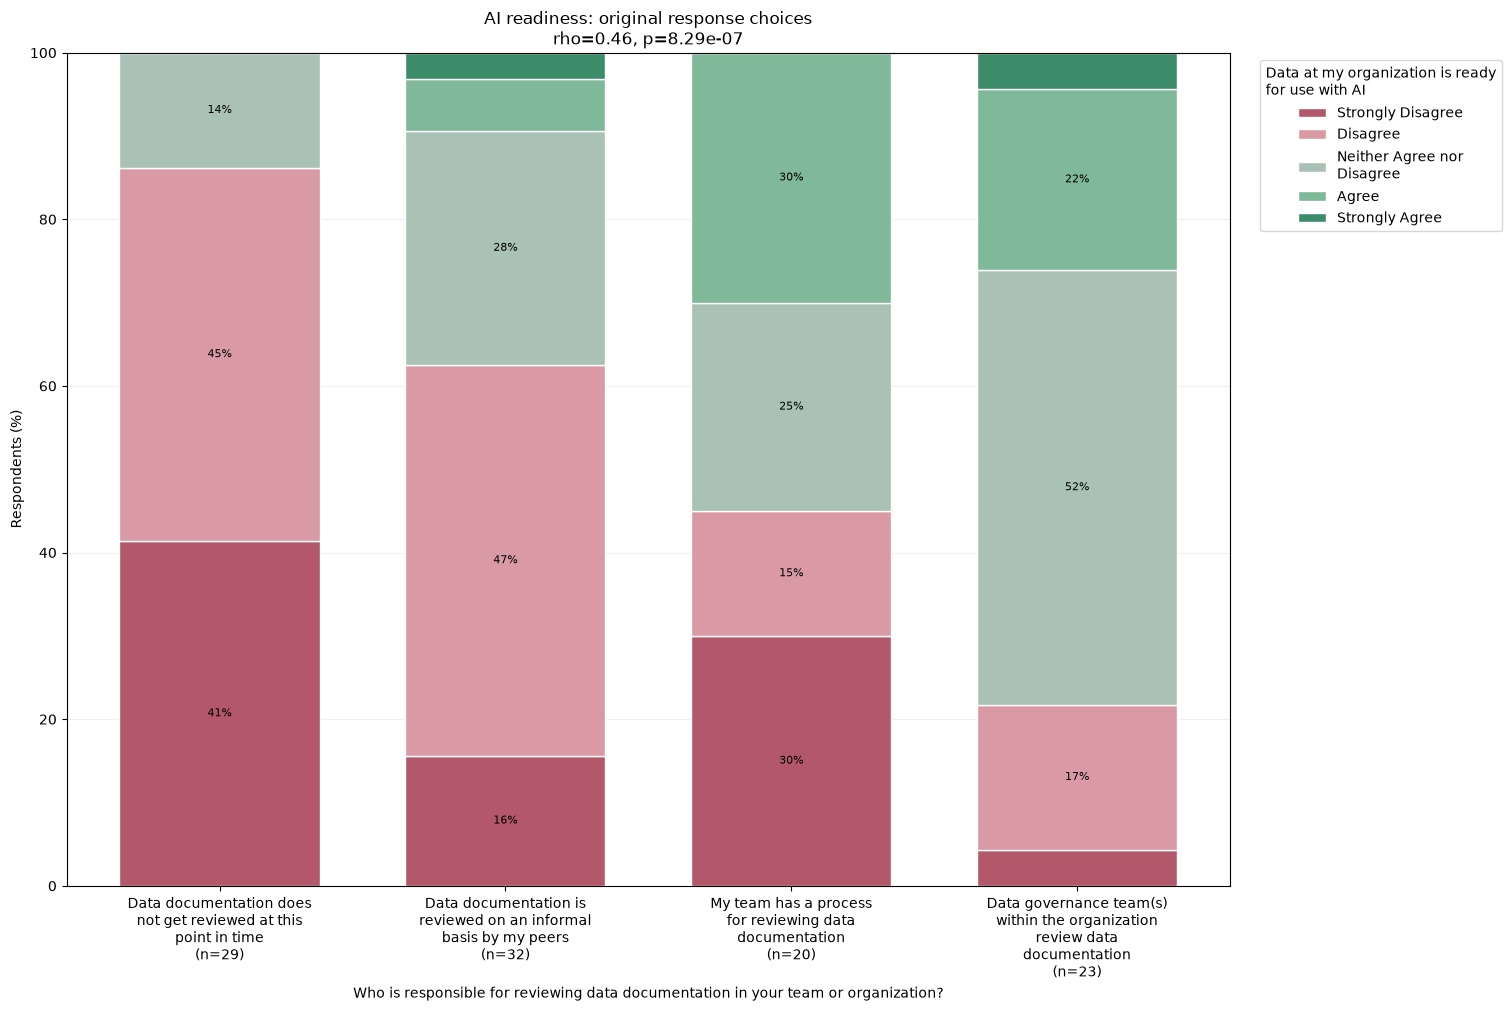

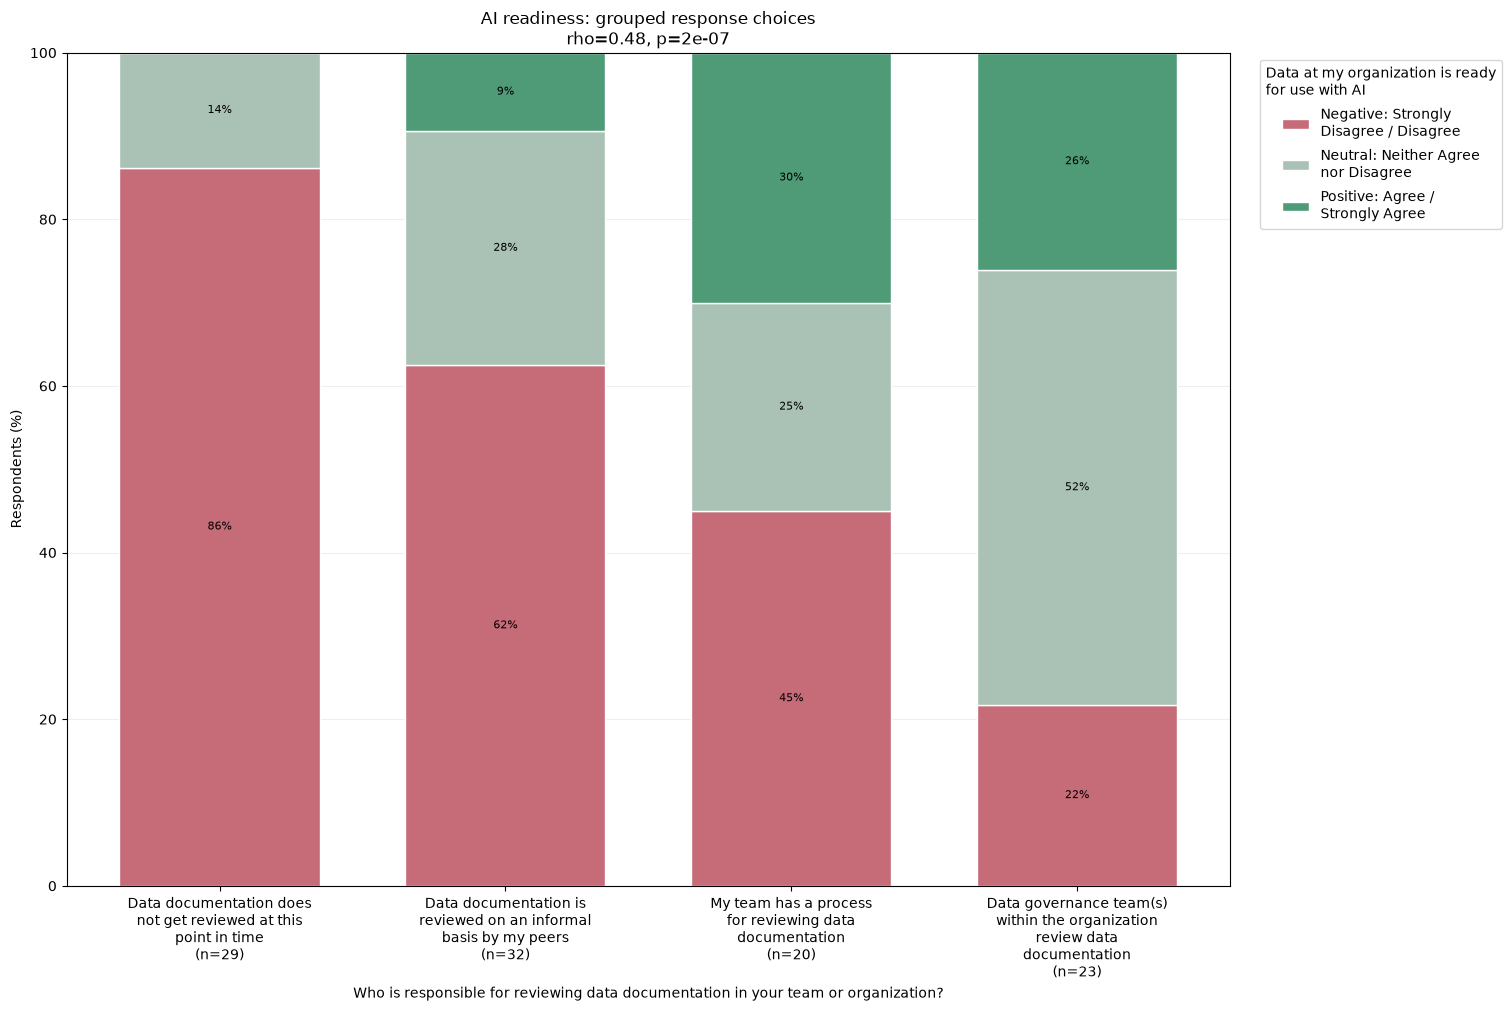

In [72]:
def plot_action_ai_stacked_bars(title, percentages, ratings, colors, labels, rho, p_value):
    figure, axis = plt.subplots(figsize=(15, 10), constrained_layout=True)
    bottom = [0.0] * len(action_ratings)
    for outcome_rating, color in zip(ratings, colors):
        heights = percentages.loc[action_ratings, outcome_rating].fillna(0).to_list()
        axis.bar(
            range(len(action_ratings)),
            heights,
            bottom=bottom,
            width=0.7,
            color=color,
            edgecolor="white",
            label=fill(labels[outcome_rating], width=24),
        )
        for position, height, start in zip(range(len(action_ratings)), heights, bottom):
            if height >= 8:
                axis.text(
                    position,
                    start + height / 2,
                    f"{height:.0f}%",
                    ha="center",
                    va="center",
                    fontsize=8,
                )
        bottom = [start + height for start, height in zip(bottom, heights)]

    axis.set_title(f"{title}\nrho={rho:.2f}, p={p_value:.3g}")
    axis.set_xticks(range(len(action_ratings)), labels=tick_labels, rotation=0, ha="center")
    axis.set_xlabel(fill(action_question, width=90))
    axis.set_ylabel("Respondents (%)")
    axis.set_ylim(0, 100)
    axis.grid(axis="y", alpha=0.2)
    axis.set_axisbelow(True)
    axis.legend(title=fill(ai_question, width=35), bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.show()


plot_action_ai_stacked_bars(
    "AI readiness: original response choices",
    original_percent,
    ai_ratings,
    original_colors,
    ai_choice_labels,
    original_rho,
    original_p,
)
plot_action_ai_stacked_bars(
    "AI readiness: grouped response choices",
    recoded_percent,
    recoded_ratings,
    recoded_colors,
    recoded_choice_labels,
    recoded_rho,
    recoded_p,
)

## Action and self-assessment outcome correlations

Spearman's rank correlation summarizes the association between each action rating and each self-assessment outcome. Each pair uses completed respondents with values for both columns; only results with raw p-values below 0.025 are displayed.

In [58]:
self_assess_columns = [
    column for column in rating_columns if column.startswith("self_assess_")
]
self_assess_correlations = display_original_correlations(
    completed, action_analysis_columns, self_assess_columns
)

### self_assess_value

,action,spearman_rho,p_value,n
0,actions_endorse_2,0.452301,0.000004,96
1,actions_endorse_1,0.411993,0.000008,110
2,actions_leadership_2,0.404121,0.000013,109
3,actions_inventory_1,0.364096,0.000092,110
4,actions_document_1,0.358162,0.000122,110
5,actions_audit_2,0.363926,0.000198,100
6,actions_leadership_1,0.321558,0.000432,116
7,actions_inventory_2,0.277720,0.003458,109
8,actions_audit_1,0.280470,0.003929,104
9,actions_document_2,0.230308,0.018100,105


### self_assess_trust

,action,spearman_rho,p_value,n
0,actions_leadership_2,0.426404,0.000003,110
1,actions_endorse_1,0.415398,0.000006,110
2,actions_document_1,0.410855,0.000008,110
3,actions_inventory_1,0.400870,0.000014,110
4,actions_endorse_2,0.416090,0.000025,96
5,actions_inventory_2,0.350404,0.000175,110
6,actions_document_2,0.349701,0.000256,105
7,actions_leadership_1,0.332721,0.000263,116
8,actions_audit_1,0.321146,0.000837,105
9,actions_audit_2,0.312054,0.001574,100


### self_assess_secure

,action,spearman_rho,p_value,n
0,actions_endorse_1,0.367869,0.000083,109
1,actions_inventory_2,0.352715,0.000169,109
2,actions_leadership_2,0.306552,0.001187,109
3,actions_endorse_2,0.325531,0.001286,95
4,actions_leadership_1,0.228702,0.013954,115
5,actions_document_1,0.228152,0.017029,109


## Action rating 5 vs. lower ratings

For each action and AI/self-assessment outcome, compare action rating `5` with ratings `2–4` (excluding `1`, “I don't do this”). An outcome is positive when its original rating is `4` or `5`; ratings `1–3` are grouped as non-positive. “Don't know” (`9`) is excluded. Relative increase is descriptive; Fisher's exact p-value tests the two-by-two comparison. These are unadjusted p-values and associations do not imply causation.

In [59]:
outcome_columns = [*ai_columns, *self_assess_columns]
comparison_rows = []

for action_column, analysis_action_column in action_analysis_columns.items():
    for outcome_column in outcome_columns:
        recoded_outcome_column = f"{outcome_column}_recoded"
        paired = completed[[analysis_action_column, recoded_outcome_column]].replace(
            9, float("nan")
        ).dropna()
        paired = paired.loc[paired[analysis_action_column].isin([2, 3, 4, 5])]

        group_5 = paired.loc[paired[analysis_action_column] == 5, recoded_outcome_column]
        group_2_to_4 = paired.loc[
            paired[analysis_action_column].isin([2, 3, 4]), recoded_outcome_column
        ]
        positive_5 = int(group_5.eq("positive").sum())
        positive_2_to_4 = int(group_2_to_4.eq("positive").sum())
        n_5 = len(group_5)
        n_2_to_4 = len(group_2_to_4)
        rate_5 = positive_5 / n_5 if n_5 else float("nan")
        rate_2_to_4 = positive_2_to_4 / n_2_to_4 if n_2_to_4 else float("nan")

        if n_5 and n_2_to_4:
            test = fisher_exact(
                [
                    [positive_5, n_5 - positive_5],
                    [positive_2_to_4, n_2_to_4 - positive_2_to_4],
                ],
                alternative="two-sided",
            )
            p_value = test.pvalue
        else:
            p_value = float("nan")

        comparison_rows.append(
            {
                "action": action_column,
                "outcome": outcome_column,
                "rating_5_positive/n (%)": (
                    f"{positive_5}/{n_5} ({rate_5:.1%})" if n_5 else "0/0 (n/a)"
                ),
                "ratings_2-4_positive/n (%)": (
                    f"{positive_2_to_4}/{n_2_to_4} ({rate_2_to_4:.1%})"
                    if n_2_to_4
                    else "0/0 (n/a)"
                ),
                "difference_pp": (
                    (rate_5 - rate_2_to_4) * 100
                    if n_5 and n_2_to_4
                    else float("nan")
                ),
                "relative_increase_pct": (
                    (rate_5 / rate_2_to_4 - 1) * 100
                    if n_5 and n_2_to_4 and rate_2_to_4 > 0
                    else float("nan")
                ),
                "fisher_p": p_value,
            }
        )

rating_5_comparison = pd.DataFrame(comparison_rows)
for outcome_column in outcome_columns:
    outcome_table = rating_5_comparison.loc[
        (rating_5_comparison["outcome"] == outcome_column)
        & (rating_5_comparison["fisher_p"] < 0.05),
        [
            "action",
            "rating_5_positive/n (%)",
            "ratings_2-4_positive/n (%)",
            "difference_pp",
            "relative_increase_pct",
            "fisher_p",
        ],
    ].sort_values("relative_increase_pct", ascending=False, na_position="last")
    display(Markdown(f"### {outcome_column}"))
    display(
        outcome_table.reset_index(drop=True).style.format(
            {
                "difference_pp": "{:+.1f}",
                "relative_increase_pct": "{:+.1f}%",
                "fisher_p": "{:.3g}",
            },
            na_rep="n/a",
        )
    )

### ai_readiness

,action,rating_5_positive/n (%),ratings_2-4_positive/n (%),difference_pp,relative_increase_pct,fisher_p
0,actions_leadership_2,6/10 (60.0%),11/101 (10.9%),+49.1,+450.9%,0.000785
1,actions_endorse_2,8/22 (36.4%),7/76 (9.2%),+27.2,+294.8%,0.00449
2,actions_leadership_1,14/56 (25.0%),5/62 (8.1%),+16.9,+210.0%,0.0222


### ai_results

,action,rating_5_positive/n (%),ratings_2-4_positive/n (%),difference_pp,relative_increase_pct,fisher_p
0,actions_leadership_2,6/10 (60.0%),18/101 (17.8%),+42.2,+236.7%,0.00658
1,actions_endorse_2,9/22 (40.9%),13/76 (17.1%),+23.8,+139.2%,0.0387
2,actions_leadership_1,17/56 (30.4%),8/62 (12.9%),+17.5,+135.3%,0.0249


### ai_responsibility

...

,action,rating_5_positive/n (%),ratings_2-4_positive/n (%),difference_pp,relative_increase_pct,fisher_p
0,actions_endorse_2,14/22 (63.6%),14/76 (18.4%),+45.2,+245.5%,9.62e-05
1,actions_audit_2,13/25 (52.0%),14/77 (18.2%),+33.8,+186.0%,0.00162
2,actions_audit_1,12/23 (52.2%),16/83 (19.3%),+32.9,+170.7%,0.00291
3,actions_document_1,14/32 (43.8%),15/80 (18.8%),+25.0,+133.3%,0.00896
4,actions_inventory_1,13/29 (44.8%),16/83 (19.3%),+25.6,+132.5%,0.0125
5,actions_inventory_2,14/31 (45.2%),16/80 (20.0%),+25.2,+125.8%,0.0158
6,actions_endorse_1,12/25 (48.0%),20/87 (23.0%),+25.0,+108.8%,0.0228


### self_assess_trust

,action,rating_5_positive/n (%),ratings_2-4_positive/n (%),difference_pp,relative_increase_pct,fisher_p
0,actions_document_1,25/32 (78.1%),32/80 (40.0%),+38.1,+95.3%,0.000323
1,actions_audit_1,19/23 (82.6%),36/83 (43.4%),+39.2,+90.5%,0.000894
2,actions_inventory_1,22/29 (75.9%),36/83 (43.4%),+32.5,+74.9%,0.00275
3,actions_leadership_2,9/10 (90.0%),52/101 (51.5%),+38.5,+74.8%,0.0217
4,actions_audit_2,19/25 (76.0%),34/77 (44.2%),+31.8,+72.1%,0.00622
5,actions_endorse_1,18/25 (72.0%),40/87 (46.0%),+26.0,+56.6%,0.0248
6,actions_leadership_1,37/56 (66.1%),27/62 (43.5%),+22.5,+51.7%,0.0168
7,actions_inventory_2,22/31 (71.0%),38/80 (47.5%),+23.5,+49.4%,0.0338


### self_assess_secure

,action,rating_5_positive/n (%),ratings_2-4_positive/n (%),difference_pp,relative_increase_pct,fisher_p


## Self-assessed security rating 5 vs. other action ratings

For each action, compare respondents who selected action rating `5` (strongly agree) with those who selected `2`, `3` or `4`; action ratings `1` (“I don't do this”) are excluded. The outcome is specifically `self_assess_secure == 5` versus other valid security ratings `2–4`; “don't know” (`9`) is excluded. The table reports rates, the percentage-point difference, relative increase, and two-sided Fisher exact p-value.

In [60]:
secure_comparison_rows = []
secure_column = "self_assess_secure"
for action_column, analysis_action_column in action_analysis_columns.items():
    paired = completed[[analysis_action_column, secure_column]].replace(
        9, float("nan")
    ).dropna()
    paired = paired.loc[paired[analysis_action_column].isin([2, 3, 4, 5])]

    group_5 = paired.loc[paired[analysis_action_column] == 5, secure_column]
    group_2_to_3 = paired.loc[
        paired[analysis_action_column].isin([2, 3, 4]), secure_column
    ]
    secure_5_count = int(group_5.eq(5).sum())
    secure_2_to_3_count = int(group_2_to_3.eq(5).sum())
    n_action_5 = len(group_5)
    n_action_2_to_3 = len(group_2_to_3)
    rate_action_5 = secure_5_count / n_action_5 if n_action_5 else float("nan")
    rate_action_2_to_3 = (
        secure_2_to_3_count / n_action_2_to_3 if n_action_2_to_3 else float("nan")
    )

    if n_action_5 and n_action_2_to_3:
        test = fisher_exact(
            [
                [secure_5_count, n_action_5 - secure_5_count],
                [secure_2_to_3_count, n_action_2_to_3 - secure_2_to_3_count],
            ],
            alternative="two-sided",
        )
        p_value = test.pvalue
    else:
        p_value = float("nan")

    secure_comparison_rows.append(
        {
            "action": action_column,
            "action_5_secure_5/n (%)": (
                f"{secure_5_count}/{n_action_5} ({rate_action_5:.1%})"
                if n_action_5
                else "0/0 (n/a)"
            ),
            "action_2-3_secure_5/n (%)": (
                f"{secure_2_to_3_count}/{n_action_2_to_3} ({rate_action_2_to_3:.1%})"
                if n_action_2_to_3
                else "0/0 (n/a)"
            ),
            "difference_pp": (
                (rate_action_5 - rate_action_2_to_3) * 100
                if n_action_5 and n_action_2_to_3
                else float("nan")
            ),
            "relative_increase_pct": (
                (rate_action_5 / rate_action_2_to_3 - 1) * 100
                if n_action_5 and n_action_2_to_3 and rate_action_2_to_3 > 0
                else float("nan")
            ),
            "fisher_p": p_value,
        }
    )

secure_rating_comparison = pd.DataFrame(secure_comparison_rows)
secure_significant_comparison = secure_rating_comparison.loc[
    secure_rating_comparison["fisher_p"] < 0.05
].sort_values("relative_increase_pct", ascending=False, na_position="last")
display(
    secure_significant_comparison.reset_index(drop=True).style.format(
        {
            "difference_pp": "{:+.1f}",
            "relative_increase_pct": "{:+.1f}%",
            "fisher_p": "{:.3g}",
        },
        na_rep="n/a",
    )
)

,action,action_5_secure_5/n (%),action_2-3_secure_5/n (%),difference_pp,relative_increase_pct,fisher_p
0,actions_audit_2,13/25 (52.0%),17/74 (23.0%),+29.0,+126.4%,0.0109
1,actions_document_2,13/24 (54.2%),20/80 (25.0%),+29.2,+116.7%,0.0116
2,actions_audit_1,11/23 (47.8%),19/81 (23.5%),+24.4,+103.9%,0.0355
3,actions_endorse_1,12/25 (48.0%),21/84 (25.0%),+23.0,+92.0%,0.0455
4,actions_document_1,14/31 (45.2%),19/78 (24.4%),+20.8,+85.4%,0.0398


## Positive AI outcomes by industry

Grouped bars show the percentage of valid AI-metric responses rated positive (`4` or `5`) within each industry. Industries with fewer than 5 completed responses are combined into `Other`; its rates are pooled from valid metric responses. Missing metric responses are excluded from each metric's denominator. X-axis labels show completed-response totals.

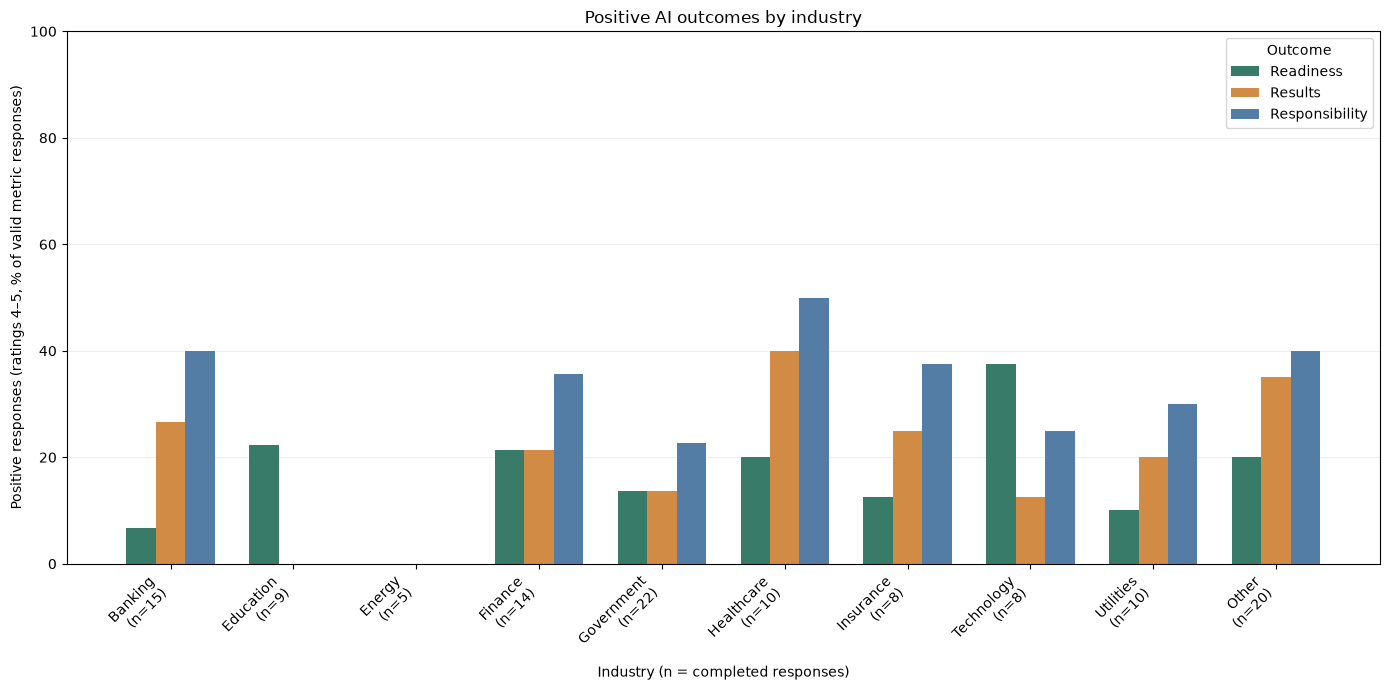

In [61]:
plot_positive_metrics_by_category(
    completed,
    "industry",
    ai_metric_columns,
    "Positive AI outcomes by industry",
)

## Positive self-assessment outcomes by industry

Grouped bars show the percentage of valid self-assessment responses rated positive (`4` or `5`) within each industry. As in the AI chart above, industries with fewer than 5 completed responses are combined into `Other`. Missing metric responses are excluded from each metric's denominator.

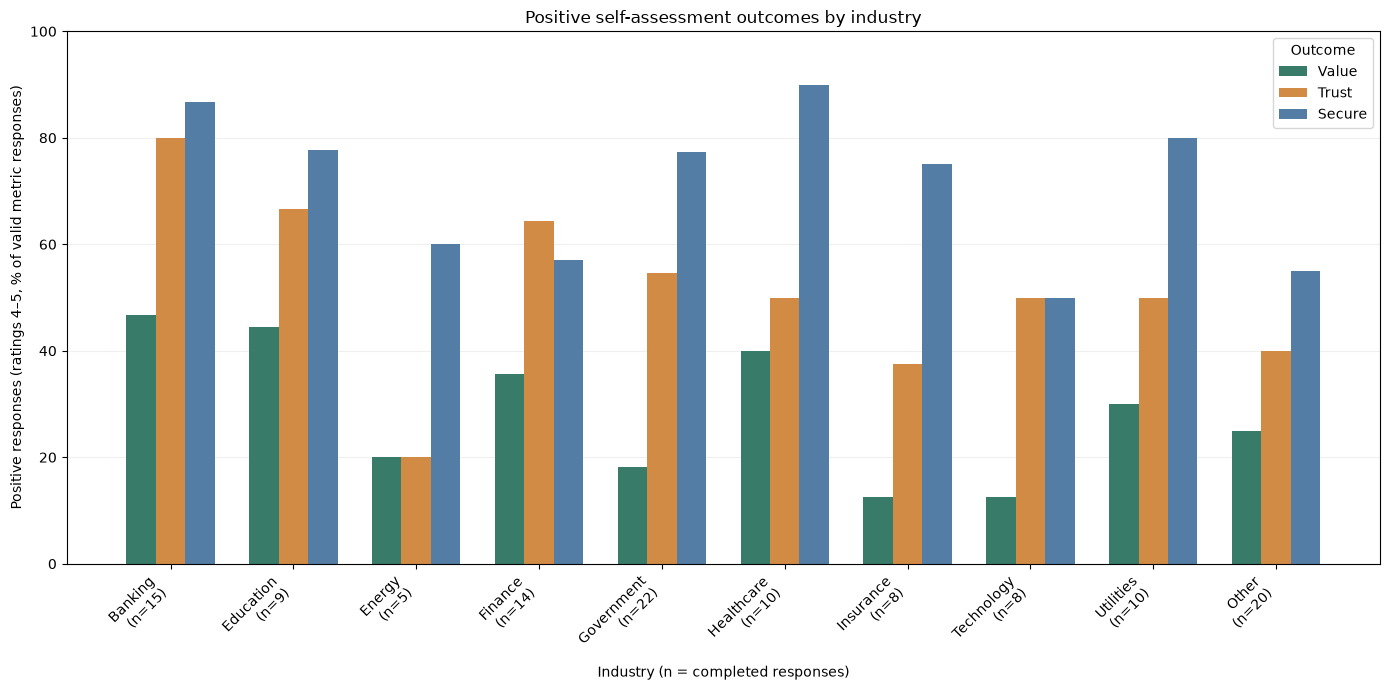

In [62]:
self_assessment_columns = [
    "self_assess_value",
    "self_assess_trust",
    "self_assess_secure",
]
plot_positive_metrics_by_category(
    completed,
    "industry",
    self_assessment_columns,
    "Positive self-assessment outcomes by industry",
)

## Positive AI outcomes by job role

This chart uses the same grouped-bar calculation as the industry charts. Job roles with fewer than 5 completed responses are pooled into `Other`.

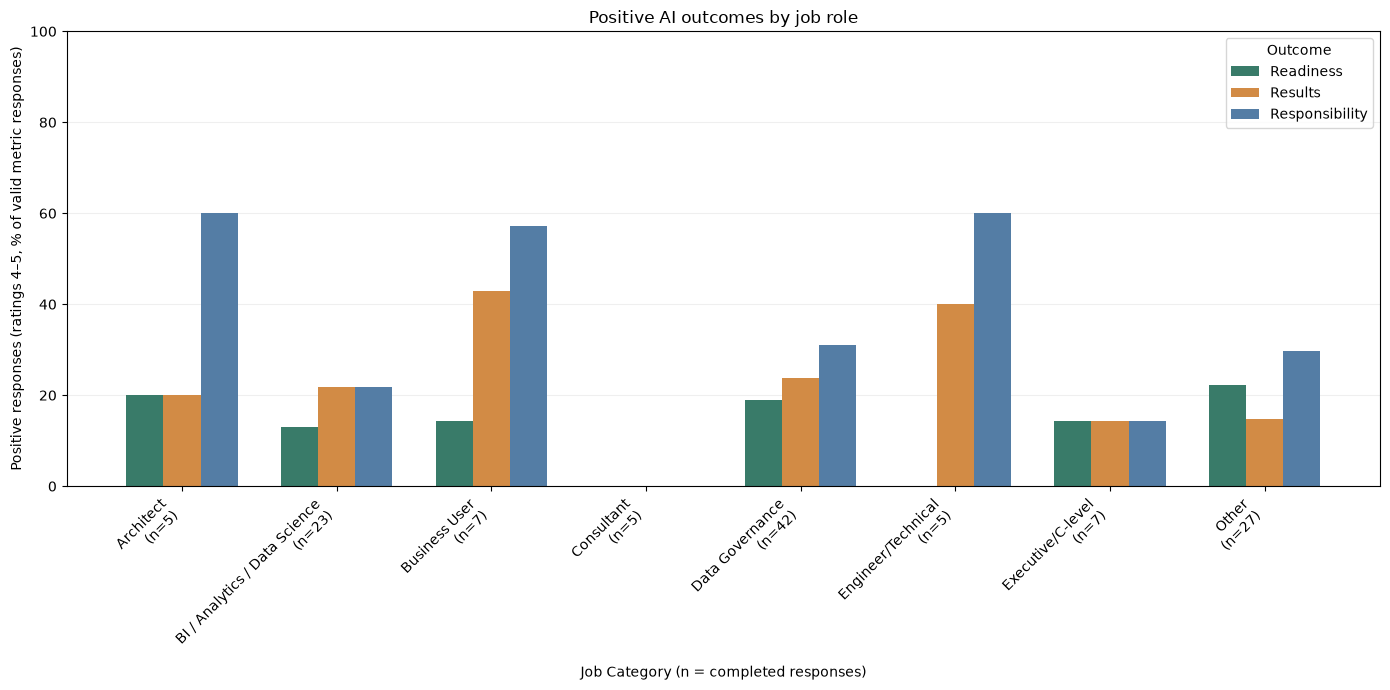

In [63]:
plot_positive_metrics_by_category(
    completed,
    "job_category",
    ai_metric_columns,
    "Positive AI outcomes by job role",
)

## Positive self-assessment outcomes by job role

This chart uses the same grouped-bar calculation as the other category charts. Job roles with fewer than 5 completed responses are pooled into `Other`.

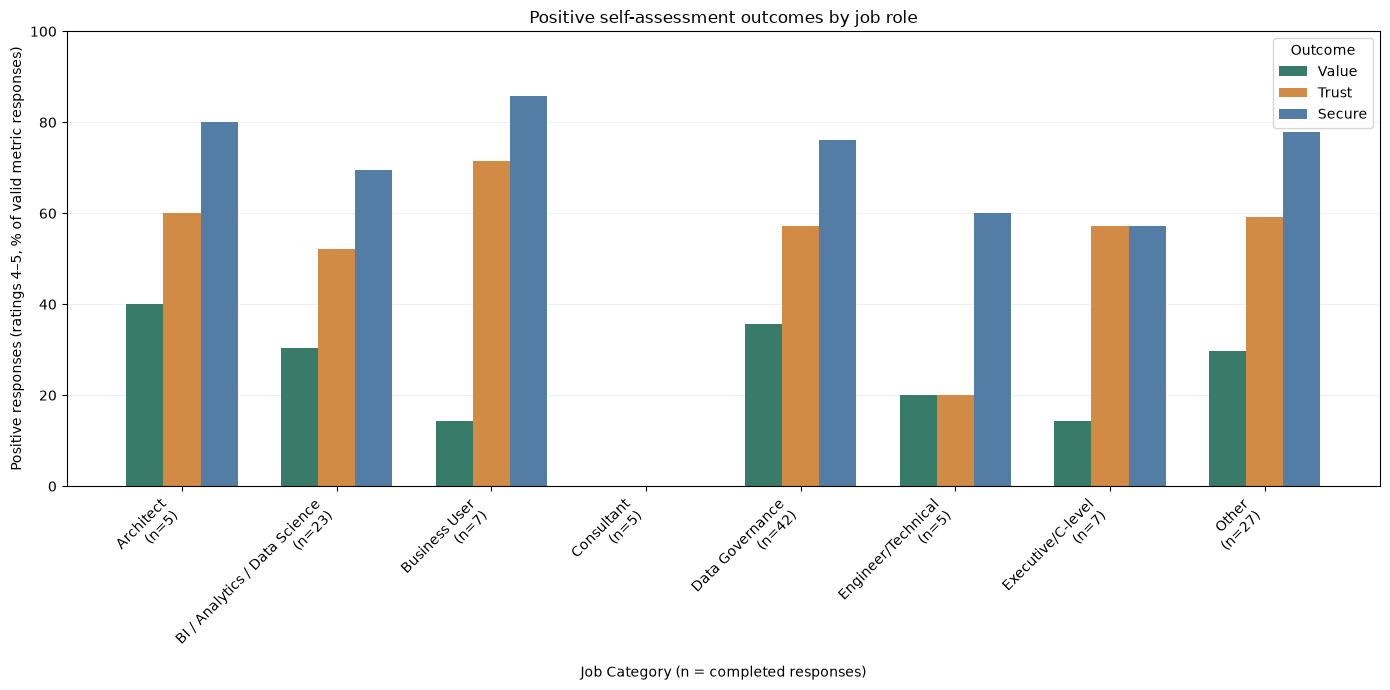

In [64]:
plot_positive_metrics_by_category(
    completed,
    "job_category",
    self_assessment_columns,
    "Positive self-assessment outcomes by job role",
)